In [ ]:

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import heapq

from scipy.optimize import linprog
from IPython.display import display, Markdown


# DATOS DEL PROBLEMA 

NODOS = list(range(1, 10))

ORIGEN = 1
DESTINO = 9

# (Origen, Destino, Costo)
ARCOS = [
    (1, 2, 4),
    (1, 3, 2),
    (2, 3, 2),
    (3, 2, 4),
    (2, 4, 7),
    (3, 4, 9),
    (3, 5, 6),
    (5, 4, 2),
    (4, 6, 1),
    (4, 7, 5),
    (5, 6, 4),
    (5, 7, 3),
    (5, 8, 2),
    (7, 6, 4),
    (6, 7, 1),
    (6, 9, 5),
    (7, 8, 3),
    (8, 7, 2),
    (7, 9, 5),
    (8, 9, 6)
]

print("SISTEMA DE RUTA MÁS CORTA")
print("========================")
print("Número de nodos:", len(NODOS))
print("Número de conexiones:", len(ARCOS))
print("Nodo de origen:", ORIGEN)
print("Nodo de destino:", DESTINO)

SISTEMA DE RUTA MÁS CORTA
Número de nodos: 9
Número de conexiones: 20
Nodo de origen: 1
Nodo de destino: 9


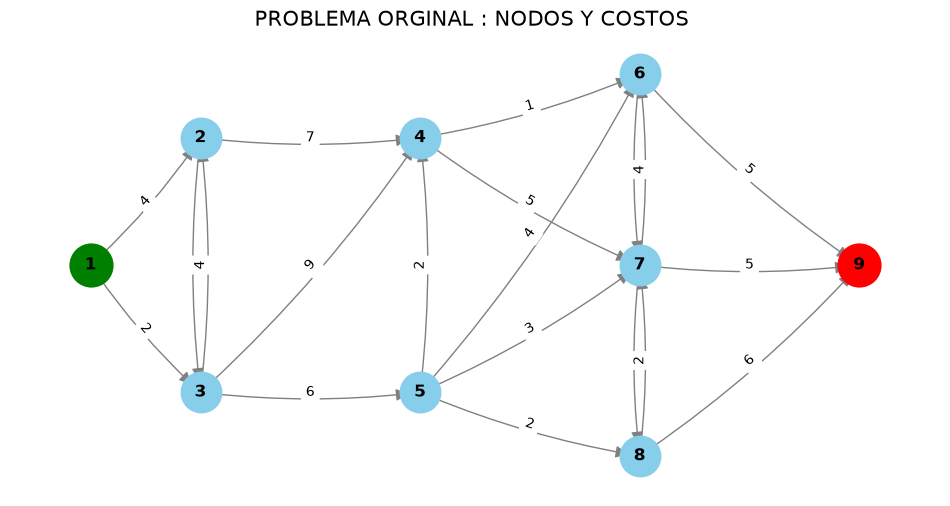

In [3]:
# LA REPRESENTACION GRÁFICA DE LA RED 
G = nx.DiGraph()

for nodo in NODOS:
    G.add_node(nodo)

for i, j, costo in ARCOS:
    G.add_edge(i, j, weight=costo)

# POSICIONES  Y ORGANIZACION DE LOS NODOS 
posiciones = {
    1: (0, 2),
    2: (1, 3),
    3: (1, 1),
    4: (3, 3),
    5: (3, 1),
    6: (5, 3.5),
    7: (5, 2),
    8: (5, 0.5),
    9: (7, 2)
}

def graficar_red(ruta=None, titulo="Red de rutas"):

    plt.figure(figsize=(12, 6))

    nx.draw_networkx_nodes(
        G, posiciones,
        node_size=850,
        node_color="skyblue"
    )

    nx.draw_networkx_labels(
        G, posiciones,
        font_size=12,
        font_weight="bold"
    )

    nx.draw_networkx_edges(
        G, posiciones,
        edge_color="gray",
        arrows=True,
        arrowsize=18,
        connectionstyle="arc3,rad=0.06"
    )

    etiquetas = nx.get_edge_attributes(G, "weight")

    nx.draw_networkx_edge_labels(
        G, posiciones,
        edge_labels=etiquetas,
        font_size=10,
        label_pos=0.5
    )

    nx.draw_networkx_nodes(
        G, posiciones,
        nodelist=[ORIGEN],
        node_color="green",
        node_size=950
    )

    nx.draw_networkx_nodes(
        G, posiciones,
        nodelist=[DESTINO],
        node_color="red",
        node_size=950
    )

    if ruta:

        aristas_ruta = [
            (ruta[i], ruta[i+1])
            for i in range(len(ruta)-1)
        ]

        nx.draw_networkx_edges(
            G, posiciones,
            edgelist=aristas_ruta,
            edge_color="red",
            width=3.5,
            arrows=True,
            arrowsize=23
        )

    plt.title(titulo, fontsize=15)
    plt.axis("off")
    plt.show()


graficar_red(titulo="PROBLEMA ORGINAL : NODOS Y COSTOS ")

RESULTADOS DEL ALGORITMO DE DIJKSTRA

Nodos procesados: [1, 3, 2, 5, 4, 8, 6, 7, 9]

DISTANCIAS MÍNIMAS
Nodo 1: 0
Nodo 2: 4
Nodo 3: 2
Nodo 4: 10
Nodo 5: 8
Nodo 6: 11
Nodo 7: 11
Nodo 8: 10
Nodo 9: 16

PREDECESORES
Nodo 1: None
Nodo 2: 1
Nodo 3: 1
Nodo 4: 5
Nodo 5: 3
Nodo 6: 4
Nodo 7: 5
Nodo 8: 5
Nodo 9: 8

RUTA MÁS CORTA:
1 -> 3 -> 5 -> 8 -> 9

COSTO MÍNIMO: 16


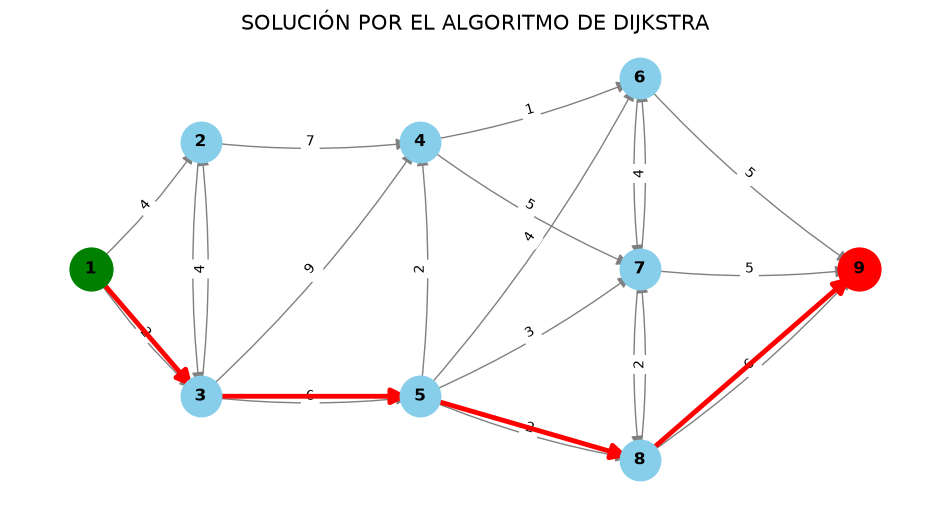

In [21]:

# ALGORITMO DE DIJKSTRA


def resolver_dijkstra():

    distancias = {
        nodo: float("inf")
        for nodo in NODOS
    }

    anteriores = {
        nodo: None
        for nodo in NODOS
    }

    distancias[ORIGEN] = 0

    cola = [(0, ORIGEN)]
    procesados = []

    while cola:

        distancia, actual = heapq.heappop(cola)

        if distancia > distancias[actual]:
            continue

        if actual in procesados:
            continue

        procesados.append(actual)

        if actual == DESTINO:
            break

        for vecino, costo in G[actual].items():

            nueva = distancia + costo["weight"]

            if nueva < distancias[vecino]:

                distancias[vecino] = nueva
                anteriores[vecino] = actual

                heapq.heappush(
                    cola,
                    (nueva, vecino)
                )

    # Reconstrucción de la ruta
    ruta = []
    actual = DESTINO

    while actual is not None:
        ruta.append(actual)
        actual = anteriores[actual]

    ruta.reverse()

    return distancias, anteriores, ruta, procesados


distancias, anteriores, ruta_dijkstra, procesados = resolver_dijkstra()

print("RESULTADOS DEL ALGORITMO DE DIJKSTRA")


print("\nNodos procesados:", procesados)

print("\nDISTANCIAS MÍNIMAS")

for nodo, distancia in distancias.items():
    print(f"Nodo {nodo}: {distancia}")

print("\nPREDECESORES")

for nodo, anterior in anteriores.items():
    print(f"Nodo {nodo}: {anterior}")

print("\nRUTA MÁS CORTA:")
print(" -> ".join(map(str, ruta_dijkstra)))

print("\nCOSTO MÍNIMO:", distancias[DESTINO])

graficar_red(
    ruta_dijkstra,
    "SOLUCIÓN POR EL ALGORITMO DE DIJKSTRA"
)

In [20]:

# FUNCION OBJETIVO Y RESTRICCIONES DEL PL



print("MODELO DE PROGRAMACION LINEAL")


# 1. FUNCION OBJETIVO

print("\nFUNCION OBJETIVO: MINIMIZAR Z\n")

terminos = []

for i, j, costo in ARCOS:
    terminos.append(f"{costo}x{i}{j}")

print("Min Z = " + " + ".join(terminos))


# 2. RESTRICCIONES DE CONSERVACION DE FLUJO

print("\nRESTRICCIONES:\n")

for nodo in NODOS:

    salidas = [
        f"x{i}{j}"
        for i, j, costo in ARCOS
        if i == nodo
    ]

    entradas = [
        f"x{i}{j}"
        for i, j, costo in ARCOS
        if j == nodo
    ]

    expresion = " + ".join(salidas) if salidas else "0"

    expresion += " - "

    expresion += " - ".join(entradas) if entradas else "0"

    if nodo == ORIGEN:
        valor = 1
    elif nodo == DESTINO:
        valor = -1
    else:
        valor = 0

    print(f"Nodo {nodo}: {expresion} = {valor}")




MODELO DE PROGRAMACION LINEAL

FUNCION OBJETIVO: MINIMIZAR Z

Min Z = 4x12 + 2x13 + 2x23 + 4x32 + 7x24 + 9x34 + 6x35 + 2x54 + 1x46 + 5x47 + 4x56 + 3x57 + 2x58 + 4x76 + 1x67 + 5x69 + 3x78 + 2x87 + 5x79 + 6x89

RESTRICCIONES:

Nodo 1: x12 + x13 - 0 = 1
Nodo 2: x23 + x24 - x12 - x32 = 0
Nodo 3: x32 + x34 + x35 - x13 - x23 = 0
Nodo 4: x46 + x47 - x24 - x34 - x54 = 0
Nodo 5: x54 + x56 + x57 + x58 - x35 = 0
Nodo 6: x67 + x69 - x46 - x56 - x76 = 0
Nodo 7: x76 + x78 + x79 - x47 - x57 - x67 - x87 = 0
Nodo 8: x87 + x89 - x58 - x78 = 0
Nodo 9: 0 - x69 - x79 - x89 = -1


In [9]:

# RESOLVER PROGRAMACIÓN LINEAL


# Coeficientes de la función objetivo
c = np.array([
    costo for i, j, costo in ARCOS
], dtype=float)

# Matriz de restricciones
A_eq = np.zeros((len(NODOS), len(ARCOS)))
b_eq = np.zeros(len(NODOS))

for fila, nodo in enumerate(NODOS):

    for columna, (i, j, costo) in enumerate(ARCOS):

        if i == nodo:
            A_eq[fila, columna] += 1

        if j == nodo:
            A_eq[fila, columna] -= 1

    if nodo == ORIGEN:
        b_eq[fila] = 1

    elif nodo == DESTINO:
        b_eq[fila] = -1

    else:
        b_eq[fila] = 0

# Límites de las variables
limites = [(0, 1) for _ in ARCOS]

# Ejecutar el solucionador
resultado = linprog(
    c,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=limites,
    method="highs"
)

if resultado.success:

  
    print("SOLUCIÓN ÓPTIMA POR PROGRAMACIÓN LINEAL")


    print("\nEstado:", resultado.message)

    print("\nValor óptimo de Z:", resultado.fun)

else:

    print("Error al resolver el modelo:")
    print(resultado.message)

SOLUCIÓN ÓPTIMA POR PROGRAMACIÓN LINEAL

Estado: Optimization terminated successfully. (HiGHS Status 7: Optimal)

Valor óptimo de Z: 16.0


RUTA ENCONTRADA POR PROGRAMACIÓN LINEAL:
1 -> 3 -> 5 -> 4 -> 6 -> 9

COSTO TOTAL: 16.0


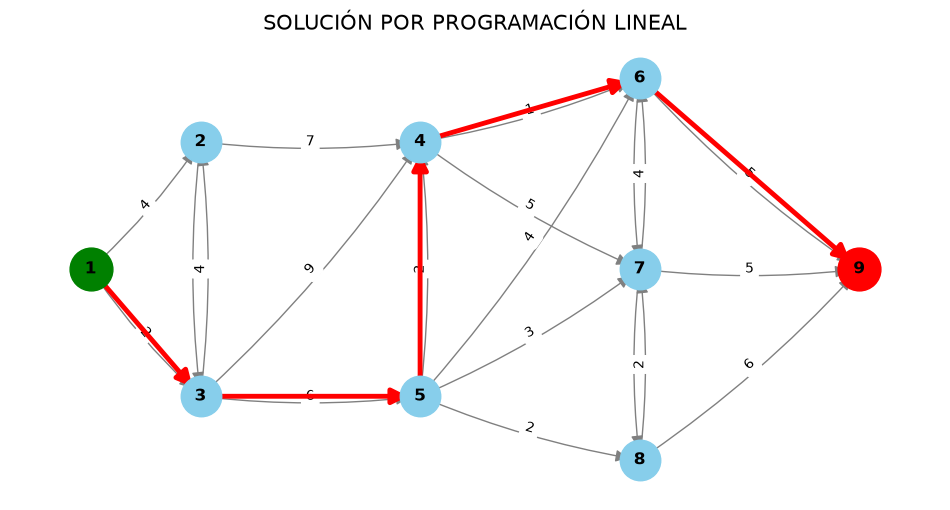

In [11]:
# Obtener las conexiones seleccionadas
arcos_activos = []

for (i, j, costo), valor in zip(ARCOS, resultado.x):

    if valor > 0.5:
        arcos_activos.append((i, j, costo))

# Reconstruir la ruta
ruta_PL = [ORIGEN]
actual = ORIGEN

while actual != DESTINO:

    siguiente = [
        j for i, j, costo in arcos_activos
        if i == actual
    ]

    if not siguiente:
        raise ValueError("No se pudo reconstruir la ruta.")

    actual = siguiente[0]
    ruta_PL.append(actual)

print("RUTA ENCONTRADA POR PROGRAMACIÓN LINEAL:")
print(" -> ".join(map(str, ruta_PL)))

print("\nCOSTO TOTAL:", resultado.fun)

graficar_red(
    ruta_PL,
    "SOLUCIÓN POR PROGRAMACIÓN LINEAL"
)

In [13]:

# SUSTITUCIÓN EN LA FUNCIÓN OBJETIVO



print("SUSTITUCIÓN EN LA FUNCIÓN OBJETIVO")

suma = []

for (i, j, costo), valor in zip(ARCOS, resultado.x):

    valor = round(valor)

    suma.append(costo * valor)

    print(f"{costo}({valor})", end=" + ")

print("\n")

print("RESULTADO DE LA FUNCIÓN OBJETIVO:")

print("Z =", " + ".join(map(str, suma)))

print("\nZ MÍNIMO =", sum(suma))

SUSTITUCIÓN EN LA FUNCIÓN OBJETIVO
4(0) + 2(1) + 2(0) + 4(0) + 7(0) + 9(0) + 6(1) + 2(1) + 1(1) + 5(0) + 4(0) + 3(0) + 2(0) + 4(0) + 1(0) + 5(1) + 3(0) + 2(0) + 5(0) + 6(0) + 

RESULTADO DE LA FUNCIÓN OBJETIVO:
Z = 0 + 2 + 0 + 0 + 0 + 0 + 6 + 2 + 1 + 0 + 0 + 0 + 0 + 0 + 0 + 5 + 0 + 0 + 0 + 0

Z MÍNIMO = 16


In [15]:



print("COMPARACIÓN DE RESULTADOS")


print("\nMÉTODO DE DIJKSTRA")
print("Ruta:", " -> ".join(map(str, ruta_dijkstra)))
print("Costo:", distancias[DESTINO])

print("\nPROGRAMACIÓN LINEAL")
print("Ruta:", " -> ".join(map(str, ruta_PL)))
print("Costo:", resultado.fun)

print("\nVERIFICACIÓN")

if abs(distancias[DESTINO] - resultado.fun) < 1e-8:
    print("AMBOS MÉTODOS OBTUVIERON EL MISMO COSTO ÓPTIMO.")
    print("RESULTADO FINAL: Z = 16")

else:
    print("Los resultados no coinciden.")

COMPARACIÓN DE RESULTADOS

MÉTODO DE DIJKSTRA
Ruta: 1 -> 3 -> 5 -> 8 -> 9
Costo: 16

PROGRAMACIÓN LINEAL
Ruta: 1 -> 3 -> 5 -> 4 -> 6 -> 9
Costo: 16.0

VERIFICACIÓN
AMBOS MÉTODOS OBTUVIERON EL MISMO COSTO ÓPTIMO.
RESULTADO FINAL: Z = 16
